# Прогноз цены недвижимости v2: продажа + аренда


# 1. Подготовка

## 1.1 Импорты и настройки

In [1]:
import re
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error, median_absolute_error)

import lightgbm as lgb
try:
    from catboost import CatBoostRegressor
    HAS_CATBOOST = True
except ModuleNotFoundError:
    CatBoostRegressor, HAS_CATBOOST = None, False

RANDOM_STATE = 42
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.width', 200)

DATA_PATH = 'real_estate_data_2.csv'
TEST_PATH = 'test_real_estate_samples.csv'   
RESULT_PATH = 'result_real_estate_samples.csv'

STUDENT_NAME = 'Валиуллин Тимур Рафаэлевич'
STUDENT_GROUP = '23П-1'

print('lightgbm', lgb.__version__)

lightgbm 4.7.0


## 1.1 Загрузка

Смотрим на два поля, которые решают всё: `listing_type` (1 = продажа, 2 = аренда, 3 = что-то третье)

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig', low_memory=False)
print(f'Строк: {df_raw.shape[0]:,}  столбцов: {df_raw.shape[1]}')

print('\nlisting_type:')
print(df_raw['listing_type'].value_counts().to_string())
print('\nМедианная цена по типу объявления:')
print(df_raw[df_raw.price_currency == 'TRY'].groupby('listing_type')['price'].median().to_string())

Строк: 403,487  столбцов: 17

listing_type:
listing_type
1    287009
2    114236
3      2242

Медианная цена по типу объявления:
listing_type
1    270000.0
2      1200.0
3        70.0


Разница видна сразу: у типа 1 медиана около 270 тыс лир, у типа 2 — около 1200 лир. Это продажа и аренда.
Тип 3 с медианой около 90 лир — скорее всего суточная аренда, таких строк всего 2242 и в тестовом файле
их нет, поэтому не берём.

# 2. Признаки

## 2.1 Обычные признаки

Тут три неочевидных момента:

* Порядковые категории переводим в числа сами.`building_age` это строки вида `'11-15 arası'` (диапазон),
  `'40 ve üzeri'` (40 и выше) или просто `'3'`. Берём середину диапазона, а для «и выше» число × 1.2.
* Этажи В `floor_no` есть подвалы (`Kot 1`, `Bodrum Kat`), уровень входа (`Zemin Kat`),
  мансарда (`Çatı Katı`). Числом их не вытащить, прописываем словарём: подвалы в минус, вход около нуля,
  мансарда наверх.
* Мусорную площадь превращаем в пропуск, а не удаляем строку. В данных есть квартиры по 1 м² и по
  948 000 м². Если такую строку выкинуть, то в тестовом файле она всё равно придёт Поэтому ставим NaN — LightGBM и CatBoost умеют работать
  с пропусками сами.

In [3]:
# Этажи задаём вручную
FLOOR_MANUAL = {
    'Kot 4': -4, 'Kot 3': -3, 'Bodrum Kat': -3, 'Kot 2': -2, 'Kot 1': -1,
    'Bahçe katı': -0.5, 'Zemin Kat': 0, 'Giriş Katı': 0.1, 'Yüksek Giriş': 0.2,
    'Müstakil': 0.3, 'Komple': 0.4, 'Asma Kat': 0.5,
    '20 ve üzeri': 22, 'Çatı Katı': 25, 'Teras Kat': 26, 'En Üst Kat': 27,
}
GROUND_LABELS = ['Zemin Kat', 'Giriş Katı', 'Yüksek Giriş', 'Bahçe katı']
TOP_LABELS = ['Çatı Katı', 'En Üst Kat', 'Teras Kat']
SIZE_BINS = [0, 40, 60, 75, 90, 110, 130, 160, 200, 300, 500, 5000]

# Перевод турецкого текста про этаж и возраст дома в число
def to_num(value):
    text = str(value).strip()
    if text in FLOOR_MANUAL:
        return FLOOR_MANUAL[text]
    nums = re.findall(r'\d+', text)
    if not nums:
        return np.nan
    if 've üzeri' in text:          # "и выше" - берём чуть больше порога
        return float(nums[0]) * 1.2
    return sum(float(n) for n in nums) / len(nums)

# Превращение признаков
def base_features(df):
    d = pd.DataFrame(index=df.index)

    # адрес: город / округ / район
    addr = df['address'].fillna('Unknown').astype(str)
    parts = addr.str.split('/')
    d['city'] = parts.str[0]
    d['district'] = parts.str[:2].str.join('/')
    d['hood'] = addr

    # планировка "3+1" -> комнаты 3, гостиные 1
    rc = df['room_count'].fillna('').astype(str)
    sp = rc.str.extract(r'(\d+)\+(\d+)')
    d['rooms'] = pd.to_numeric(sp[0], errors='coerce')
    d['living'] = pd.to_numeric(sp[1], errors='coerce')
    d['total_rooms'] = d['rooms'] + d['living']
    d['room_key'] = rc.replace('', 'Unknown')     

    # площадь: мусор -> NaN
    size = pd.to_numeric(df['size'], errors='coerce')
    size = size.where((size >= 8) & (size <= 5000))
    d['size'] = size
    d['size_log'] = np.log1p(size)
    d['size_per_room'] = size / d['total_rooms'].replace(0, np.nan)   
    d['size_bucket'] = pd.cut(size, SIZE_BINS, labels=False).fillna(-1).astype(int).astype(str)

    # возраст дома и этажи
    d['age'] = df['building_age'].map(to_num)
    d['floors_total'] = df['total_floor_count'].map(to_num)
    d['floor'] = df['floor_no'].map(to_num)
    d['floor_ratio'] = d['floor'] / d['floors_total'].replace(0, np.nan)
    d['is_ground'] = df['floor_no'].isin(GROUND_LABELS).astype(int)
    d['is_top'] = df['floor_no'].isin(TOP_LABELS).astype(int)

    # дата публикации и сколько объявление провисело
    start = pd.to_datetime(df['start_date'], format='%m/%d/%y', errors='coerce')
    d['month'] = start.dt.month
    d['tom'] = pd.to_numeric(df['tom'], errors='coerce')

    d['sub_type'] = df['sub_type'].fillna('Unknown').astype(str)
    d['heating'] = df['heating_type'].fillna('Unknown').astype(str)

    return d.replace([np.inf, -np.inf], np.nan)


print('Проверим на первых строках:')
base_features(df_raw.head(3))[['city', 'district', 'hood', 'rooms', 'living',
                               'size', 'age', 'floor', 'sub_type']]

Проверим на первых строках:


,city,district,hood,rooms,living,size,age,floor,sub_type
0,İstanbul,İstanbul/Kartal,İstanbul/Kartal/Kordonboyu,2,1,90.0,0.0,2.0,Rezidans
1,İstanbul,İstanbul/Kartal,İstanbul/Kartal/Kordonboyu,1,0,43.0,0.0,22.0,Daire
2,Tekirdağ,Tekirdağ/Çorlu,Tekirdağ/Çorlu/Reşadiye,2,1,NaN,0.0,0.2,Daire


## 2.1 Признаки-аналоги

Идея простая. Когда риелтор оценивает квартиру, он не считает регрессию — он смотрит, за сколько
продаются **похожие квартиры рядом**. Сделаем то же самое признаком.

Берём несколько «ключей похожести» от самого точного к самому общему:

**`g_exact`** — район + тип + планировка + корзина метража
*почти тот же самый объект, k=1*

**`g_hood_rs`** — район + планировка + корзина метража
*k=2*

**`g_hood_r`** — район + планировка
*k=3*

**`g_hood_st`** — район + тип жилья
*k=3*

**`g_hood`** — весь район
*k=8*

**`g_dist_rs`** — округ + планировка + корзина метража
*k=5*

**`g_dist_st`** — округ + тип жилья
*k=5*

**`g_dist`** — весь округ
*k=15*

**`g_city_st`** — город + тип жилья
*k=20*

**`g_city`** — весь город
*k=30*

**`g_st_sb`** — тип жилья + корзина метража
*k=20*

`k` — сила сглаживания: насколько среднее группы подтягивается к общему среднему.
Чем грубее ключ, тем больше `k`. Все 11 ключей лежат в `GROUPS`, значения `k` — в `SMOOTH_K`.


In [4]:
# ключи похожести и сила сглаживания k для каждого
GROUPS = {
    'g_exact':   ['hood', 'sub_type', 'room_key', 'size_bucket'],
    'g_hood_rs': ['hood', 'room_key', 'size_bucket'],
    'g_hood_r':  ['hood', 'room_key'],
    'g_hood_st': ['hood', 'sub_type'],
    'g_hood':    ['hood'],
    'g_dist_rs': ['district', 'room_key', 'size_bucket'],
    'g_dist_st': ['district', 'sub_type'],
    'g_dist':    ['district'],
    'g_city_st': ['city', 'sub_type'],
    'g_city':    ['city'],
    'g_st_sb':   ['sub_type', 'size_bucket'],
}
# по этим ключам считаем ещё и квантили цены, а не только среднее
QUANT_GROUPS = ['g_hood', 'g_hood_r', 'g_hood_st', 'g_dist', 'g_dist_st', 'g_city']
SMOOTH_K = {'g_exact': 1, 'g_hood_rs': 2, 'g_hood_r': 3, 'g_hood_st': 3, 'g_hood': 8,
            'g_dist_rs': 5, 'g_dist_st': 5, 'g_dist': 15, 'g_city_st': 20, 'g_city': 30,
            'g_st_sb': 20}

# Склеивает несколько столбцов в один строковый ключ
def _join_key(feat, cols):
    out = feat[cols[0]].astype(str)
    for c in cols[1:]:
        out = out.str.cat(feat[c].astype(str), sep='|')
    return out

# Строит справочники "сколько стоят похожие объекты"
def fit_comp_maps(feat, y_log, ppm_log):
    global_y, global_p = float(y_log.mean()), float(ppm_log.mean())
    maps = {}
    for name, cols in GROUPS.items():
        k = SMOOTH_K[name]
        g = pd.DataFrame({'key': _join_key(feat, cols).values,
                          'y': y_log.values, 'p': ppm_log.values})
        gb = g.groupby('key')
        agg = gb.agg(y_sum=('y', 'sum'), y_n=('y', 'count'),
                     p_sum=('p', 'sum'), p_n=('p', 'count'))
        q = gb['y'].quantile([0.25, 0.75, 0.9]).unstack()
        maps[name] = pd.DataFrame({
            'y': (agg['y_sum'] + global_y * k) / (agg['y_n'] + k),
            'p': (agg['p_sum'].fillna(0) + global_p * k) / (agg['p_n'] + k),
            'n': agg['y_n'],
            'q25': q[0.25], 'q75': q[0.75], 'q90': q[0.9],
        })
    return maps, global_y, global_p

# Подставляет значения из справочников в строки
def apply_comp_maps(feat, maps, global_y, global_p):
    out = pd.DataFrame(index=feat.index)
    for name, cols in GROUPS.items():
        m = maps[name]
        key = _join_key(feat, cols)
        out[f'{name}_y'] = key.map(m['y']).astype(float).fillna(global_y)
        out[f'{name}_p'] = key.map(m['p']).astype(float).fillna(global_p)
        out[f'{name}_n'] = key.map(m['n']).astype(float).fillna(0)
        if name in QUANT_GROUPS:
            # не только средняя цена района, но и верх рынка: бывают ли тут дорогие объекты
            for qn in ('q25', 'q75', 'q90'):
                out[f'{name}_{qn}'] = key.map(m[qn]).astype(float).fillna(global_y)
            out[f'{name}_spread'] = out[f'{name}_q75'] - out[f'{name}_q25']
    size_log = feat['size_log'].fillna(np.log1p(110))
    out['comp_exact'] = out['g_exact_p'] + size_log
    out['comp_hood'] = out['g_hood_p'] + size_log
    out['comp_dist'] = out['g_dist_p'] + size_log
    return out

# То же, что apply_comp_maps, но для train - честно, по фолдам
def oof_comp_maps(feat, y_log, ppm_log, n_splits=5):
    parts = []
    for tr_idx, va_idx in KFold(n_splits, shuffle=True, random_state=RANDOM_STATE).split(feat):
        m, gy, gp = fit_comp_maps(feat.iloc[tr_idx], y_log.iloc[tr_idx], ppm_log.iloc[tr_idx])
        parts.append(apply_comp_maps(feat.iloc[va_idx], m, gy, gp))
    return pd.concat(parts).loc[feat.index]


print(f'Ключей похожести: {len(GROUPS)}, из них с квантилями: {len(QUANT_GROUPS)}')

Ключей похожести: 11, из них с квантилями: 6


## 2.2 Итоговая матрица признаков

Числовые признаки отдаём как есть (бустингу масштабирование не нужно). Три категориальных
(`sub_type`, `heating`, `city`)
Остальные категории (район, планировка) уже зашиты в признаки-аналоги, отдельно их кодировать не надо —
иначе получили бы 7842 столбца.

In [5]:
NUM_FEATURES = ['rooms', 'living', 'total_rooms', 'size', 'size_log', 'size_per_room',
                'age', 'floors_total', 'floor', 'floor_ratio', 'is_ground', 'is_top',
                'month', 'tom']
CAT_FEATURES = ['sub_type', 'heating', 'city']

# Собирает итоговую матрицу признаков для модели
def build_X(feat, enc, as_string=False):
    X = pd.concat([feat[NUM_FEATURES], enc], axis=1)
    for c in CAT_FEATURES:
        X[c] = feat[c].astype(str) if as_string else feat[c].astype('category')
    return X

# 3. Очистка и разбиение

## 3.1 Очистка

Фильтры применяем **только к обучающим данным**. На предсказании никакие строки не выбрасываем —
что пришло, то и оцениваем.

* Оставляем лиры и нужный `listing_type`.
* Режем цены по краям: для продажи 50 тыс — 20 млн лир, для аренды 350 — 60 тыс. 
* Убираем дубликаты объявлений.

In [6]:
PRICE_LIMITS = {1: (50_000, 20_000_000),   # продажа
                2: (350, 60_000)}          # аренда
DUP_KEYS = ['sub_type', 'room_count', 'size', 'address', 'floor_no', 'building_age', 'price']

# Собирает итоговую матрицу признаков для модели
def load_for_training(df_raw, listing_type, exclude_ids=()):
    lo, hi = PRICE_LIMITS[listing_type]
    d = df_raw[(df_raw.price_currency == 'TRY') & (df_raw.listing_type == listing_type)]
    steps = [('Лиры + нужный listing_type', len(df_raw) - len(d))]

    before = len(d); d = d[d.price.between(lo, hi)]
    steps.append((f'Цена вне [{lo:,}; {hi:,}]', before - len(d)))

    before = len(d); d = d[~d.id.isin(set(exclude_ids))]
    steps.append(('Строки из тестового файла', before - len(d)))

    before = len(d); d = d.drop_duplicates(subset=DUP_KEYS)
    steps.append(('Дубликаты объявлений', before - len(d)))

    print(pd.DataFrame(steps, columns=['Что убрали', 'Строк']).to_string(index=False))
    print(f'Осталось для обучения: {len(d):,}')
    return d.reset_index(drop=True)

## 3.1 Выкидываем тестовые строки

Строки из тестового файла лежат в обучающем датасете. Если их не убрать,
модель на них просто вспомнит ответ, и R2 будет не про качество, а про память.

In [7]:
df_test = pd.read_csv(TEST_PATH)
test_ids = set(df_test['id'])
print(f'Строк в тестовом файле: {len(df_test)}')
print(f'Из них нашлось в обучающем датасете по id: {df_raw.id.isin(test_ids).sum()}')
print('\nСколько продаж и аренд в тесте:')
print(df_test['listing_type'].value_counts().to_string())

Строк в тестовом файле: 20
Из них нашлось в обучающем датасете по id: 20

Сколько продаж и аренд в тесте:
listing_type
1    10
2    10


## 3.2 Разбиение на три части

Делим 65 / 15 / 20:

* **train** — на нём учимся,
* **val** — на нём останавливаем бустинг и выбираем гиперпараметры и веса бленда,
* **test** — трогаем один раз в конце.

Три части, а не две, именно потому что мы выбираем параметры по val. Если выбирать по тесту, то тест
перестаёт быть честным: мы бы в него подглядели.

In [8]:

def prepare_splits(df_raw, listing_type, exclude_ids=(), extra_drop=None):
    df = load_for_training(df_raw, listing_type, exclude_ids)
    if extra_drop is not None:              # строгий режим: убираем близнецов
        before = len(df)
        df = df[~extra_drop(df)].reset_index(drop=True)
        print(f'Строгий режим: убрали ещё {before - len(df):,} объявлений-близнецов')

    feat = base_features(df)
    price = df['price'].astype(float)
    y_log = np.log1p(price)
    ppm_log = np.log1p(price / feat['size'])   

    f_rest, f_te, y_rest, y_te, p_rest, _ = train_test_split(
        feat, y_log, ppm_log, test_size=0.20, random_state=RANDOM_STATE)
    f_tr, f_va, y_tr, y_va, p_tr, _ = train_test_split(
        f_rest, y_rest, p_rest, test_size=0.1875, random_state=RANDOM_STATE)

    enc_tr = oof_comp_maps(f_tr, y_tr, p_tr)
    maps, gy, gp = fit_comp_maps(f_tr, y_tr, p_tr)
    enc_va = apply_comp_maps(f_va, maps, gy, gp)
    enc_te = apply_comp_maps(f_te, maps, gy, gp)

    print(f'train={len(f_tr):,}  val={len(f_va):,}  test={len(f_te):,}')
    return dict(f_tr=f_tr, f_va=f_va, f_te=f_te, y_tr=y_tr, y_va=y_va, y_te=y_te,
                enc_tr=enc_tr, enc_va=enc_va, enc_te=enc_te, maps=(maps, gy, gp))

# 4. Обучение

Обучаем три модели:

* **LGBM-log** — на `log1p(price)`. Хороший MAPE, устойчивая.
* **LGBM-gamma** — на сырой цене с объективом `gamma`. Он тоже умеет работать с перекошенным таргетом,
но минимизирует ошибку уже в лирах.

Для сравнения добавляем **Ridge** как базовую линию и **CatBoost**, чтобы посмотреть, выигрывает ли
другой бустинг.

In [9]:
# Обучает все модели на одной выборке
def fit_models(S, light=False):
    X_tr, X_va = build_X(S['f_tr'], S['enc_tr']), build_X(S['f_va'], S['enc_va'])
    Xc_tr, Xc_va = build_X(S['f_tr'], S['enc_tr'], True), build_X(S['f_va'], S['enc_va'], True)
    y_tr, y_va = S['y_tr'], S['y_va']

    grid = [dict(num_leaves=63,  min_child_samples=40, learning_rate=0.06),
            dict(num_leaves=127, min_child_samples=20, learning_rate=0.05),
            dict(num_leaves=255, min_child_samples=10, learning_rate=0.04)]
    best, best_rmse = None, np.inf
    for params in grid:
        m = lgb.LGBMRegressor(n_estimators=3000, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, reg_lambda=1.0, random_state=RANDOM_STATE,
                              n_jobs=-1, verbose=-1, **params)
        m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
              callbacks=[lgb.early_stopping(100, verbose=False)])
        rmse = np.sqrt(mean_squared_error(y_va, m.predict(X_va)))
        print(f'  num_leaves={params["num_leaves"]:>3}  lr={params["learning_rate"]}  '
              f'деревьев={m.best_iteration_:>4}  RMSE(log) на val={rmse:.4f}')
        if rmse < best_rmse:
            best, best_rmse, best_params = m, rmse, params
    print(f'  выбрали: {best_params}')
    m_log = best

    smear = float(np.mean(np.exp(y_tr.values - m_log.predict(X_tr))))
    print(f'  поправка Дуана: x{smear:.4f}')

    m_gam = lgb.LGBMRegressor(objective='gamma', n_estimators=3000, learning_rate=0.05,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1,
                              verbose=-1, **{k: v for k, v in best_params.items()
                                             if k != 'learning_rate'})
    m_gam.fit(X_tr, np.expm1(y_tr), eval_set=[(X_va, np.expm1(y_va))],
              callbacks=[lgb.early_stopping(100, verbose=False)])

    m_cat, ridge = None, None
    if not light and HAS_CATBOOST:
        m_cat = CatBoostRegressor(iterations=1200, learning_rate=0.06, depth=8, l2_leaf_reg=3,
                                  random_seed=RANDOM_STATE, verbose=0, cat_features=CAT_FEATURES,
                                  early_stopping_rounds=80, thread_count=-1)
        m_cat.fit(Xc_tr, y_tr, eval_set=(Xc_va, y_va))

    if not light:
        ridge = Pipeline([
            ('prep', ColumnTransformer([
                ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                                  ('sc', StandardScaler())]),
                 [c for c in X_tr.columns if c not in CAT_FEATURES]),
                ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=200,
                                      sparse_output=False), CAT_FEATURES)])),
            ('model', Ridge(alpha=10.0))])
        ridge.fit(X_tr.assign(**{c: X_tr[c].astype(str) for c in CAT_FEATURES}), y_tr)

    return dict(m_log=m_log, m_gam=m_gam, m_cat=m_cat, ridge=ridge,
                smear=smear, params=best_params)

## 4.1 Как считаем прогноз в лирах

Каждая модель отдаёт своё, приводим всё к лирам:

* `m_log` → `expm1(прогноз) * поправка`
* `m_gam` → уже лиры
* `m_cat` → `expm1(прогноз)`

Веса бленда подбираем сеткой **по val** — по R² в лирах, то есть по той метрике, которую нам и считают.

In [10]:
# Прогнозы каждой модели по отдельности, уже в лирах
def predict_parts(M, feat, enc):
    X = build_X(feat, enc)
    out = {'LGBM-log': np.expm1(M['m_log'].predict(X)) * M['smear'],
           'LGBM-gamma': np.clip(M['m_gam'].predict(X), 1, None)}
    if M['m_cat'] is not None:
        out['CatBoost'] = np.expm1(M['m_cat'].predict(build_X(feat, enc, True)))
    if M['ridge'] is not None:
        out['Ridge'] = np.expm1(M['ridge'].predict(
            X.assign(**{c: X[c].astype(str) for c in CAT_FEATURES})))
    return out

# Подбирает веса бленда на валидации
def tune_blend(M, S):

    parts = predict_parts(M, S['f_va'], S['enc_va'])
    y_real = np.expm1(S['y_va'].values)
    has_cat = 'CatBoost' in parts
    best_w, best_r2 = None, -np.inf
    for w1 in np.arange(0, 1.01, 0.1):
        w2_max = 1.01 - w1 if has_cat else 1.01 - w1
        for w2 in np.arange(0, w2_max, 0.1):
            w3 = 1 - w1 - w2
            if not has_cat and w3 > 1e-9:
                continue
            pred = w1 * parts['LGBM-log'] + w2 * parts['LGBM-gamma']
            if w3 > 1e-9:
                pred = pred + w3 * parts['CatBoost']
            r2 = r2_score(y_real, pred)
            if r2 > best_r2:
                best_w, best_r2 = (round(float(w1), 1), round(float(w2), 1), round(float(w3), 1)), r2
    print(f'  веса (log, gamma, cat) = {best_w}, R2(TRY) на val = {best_r2:.4f}')
    return best_w

# Итоговый прогноз: взвешенная сумма прогнозов моделей
def blend_predict(M, feat, enc, weights):
    parts = predict_parts(M, feat, enc)
    w1, w2, w3 = weights
    pred = w1 * parts['LGBM-log'] + w2 * parts['LGBM-gamma']
    if w3 > 1e-9:
        pred = pred + w3 * parts['CatBoost']
    return pred

## 4.2 Обучаем. Продажа

In [11]:
print('ПРОДАЖА (listing_type = 1)')
S_sale = prepare_splits(df_raw, 1, exclude_ids=test_ids)
M_sale = fit_models(S_sale)
W_sale = tune_blend(M_sale, S_sale)

ПРОДАЖА (listing_type = 1)


                   Что убрали  Строк
   Лиры + нужный listing_type 118991
Цена вне [50,000; 20,000,000]   1312
    Строки из тестового файла     10
         Дубликаты объявлений  87714
Осталось для обучения: 195,460


train=127,049  val=29,319  test=39,092


  num_leaves= 63  lr=0.06  деревьев=2131  RMSE(log) на val=0.2987


  num_leaves=127  lr=0.05  деревьев=1751  RMSE(log) на val=0.2980


  num_leaves=255  lr=0.04  деревьев=1238  RMSE(log) на val=0.2975
  выбрали: {'num_leaves': 255, 'min_child_samples': 10, 'learning_rate': 0.04}


  поправка Дуана: x1.0085


  веса (log, gamma, cat) = (0.2, 0.8, 0.0), R2(TRY) на val = 0.6559


## 4.3 Обучаем. Аренда

In [12]:
print(' АРЕНДА (listing_type = 2) ')
S_rent = prepare_splits(df_raw, 2, exclude_ids=test_ids)
M_rent = fit_models(S_rent)
W_rent = tune_blend(M_rent, S_rent)

 АРЕНДА (listing_type = 2) 
                Что убрали  Строк
Лиры + нужный listing_type 289539
    Цена вне [350; 60,000]    814
 Строки из тестового файла     10
      Дубликаты объявлений  26015
Осталось для обучения: 87,109


train=56,620  val=13,067  test=17,422


  num_leaves= 63  lr=0.06  деревьев= 138  RMSE(log) на val=0.4115


  num_leaves=127  lr=0.05  деревьев= 158  RMSE(log) на val=0.4124


  num_leaves=255  lr=0.04  деревьев= 303  RMSE(log) на val=0.4098
  выбрали: {'num_leaves': 255, 'min_child_samples': 10, 'learning_rate': 0.04}


  поправка Дуана: x1.0199


  веса (log, gamma, cat) = (0.4, 0.0, 0.6), R2(TRY) на val = 0.5341


# 5. Метрики на тесте

Тест мы до этого момента не трогали. Считаем всё сразу:

* **R² (TRY)** — главная метрика, её от нас и хотят.
* **R² (log)** — та же доля объяснённой дисперсии, но в логарифмах. Она всегда выше, потому что в
  логарифмах дорогие выбросы не доминируют. Честно показываем обе.
* **MAPE** — средняя ошибка в процентах, самая понятная.
* **MAE / MedAE** — ошибка в лирах, средняя и медианная.

In [13]:
# Считает метрики одного прогноза
def metrics_row(name, y_real, pred):
    return {'Модель': name,
            'R2 (TRY)': r2_score(y_real, pred),
            'R2 (log)': r2_score(np.log1p(y_real), np.log1p(np.clip(pred, 0, None))),
            'MAPE %': mean_absolute_percentage_error(y_real, pred) * 100,
            'MAE': mean_absolute_error(y_real, pred),
            'MedAE': median_absolute_error(y_real, pred)}

# Таблица метрик всех моделей и бленда на тесте
def report(M, S, weights, title):
    y_real = np.expm1(S['y_te'].values)
    parts = predict_parts(M, S['f_te'], S['enc_te'])
    rows = [metrics_row(n, y_real, p) for n, p in parts.items()]
    blend = blend_predict(M, S['f_te'], S['enc_te'], weights)
    rows.append(metrics_row(f'БЛЕНД {weights}', y_real, blend))
    tbl = pd.DataFrame(rows).set_index('Модель')
    print(f'--- {title} (test, {len(y_real):,} строк) ---')
    display(tbl.round(3))
    return tbl, blend, y_real


tbl_sale, pred_sale_te, y_sale_te = report(M_sale, S_sale, W_sale, 'ПРОДАЖА')
tbl_rent, pred_rent_te, y_rent_te = report(M_rent, S_rent, W_rent, 'АРЕНДА')

--- ПРОДАЖА (test, 39,092 строк) ---


,R2 (TRY),R2 (log),MAPE %,MAE,MedAE
Модель,,,,,
LGBM-log,0.628,0.826,22.204,122254.243,38168.759
LGBM-gamma,0.627,0.819,23.102,123833.733,39150.843
CatBoost,0.629,0.819,22.648,124363.225,39630.237
Ridge,0.537,0.767,26.480,141769.425,46009.775
"БЛЕНД (0.2, 0.8, 0.0)",0.630,0.822,22.802,122883.542,38576.518


--- АРЕНДА (test, 17,422 строк) ---


,R2 (TRY),R2 (log),MAPE %,MAE,MedAE
Модель,,,,,
LGBM-log,0.537,0.713,26.025,796.360,179.224
LGBM-gamma,0.501,0.695,28.409,841.975,194.623
CatBoost,0.527,0.713,25.172,804.194,178.507
Ridge,0.478,0.682,27.039,862.808,199.183
"БЛЕНД (0.4, 0.0, 0.6)",0.537,0.718,25.264,793.652,177.848


Что тут видно:

* Ridge безнадёжно отстаёт — зависимость цены от признаков нелинейная, линейной модели её не поймать.
* `LGBM-gamma` выигрывает у `LGBM-log` именно по R² в лирах, но проигрывает по MAPE. Это ровно то, о чём
  писали выше: разные модели оптимизируют разные ошибки.
* Бленд забирает лучшее от обеих.

# 6. Графики

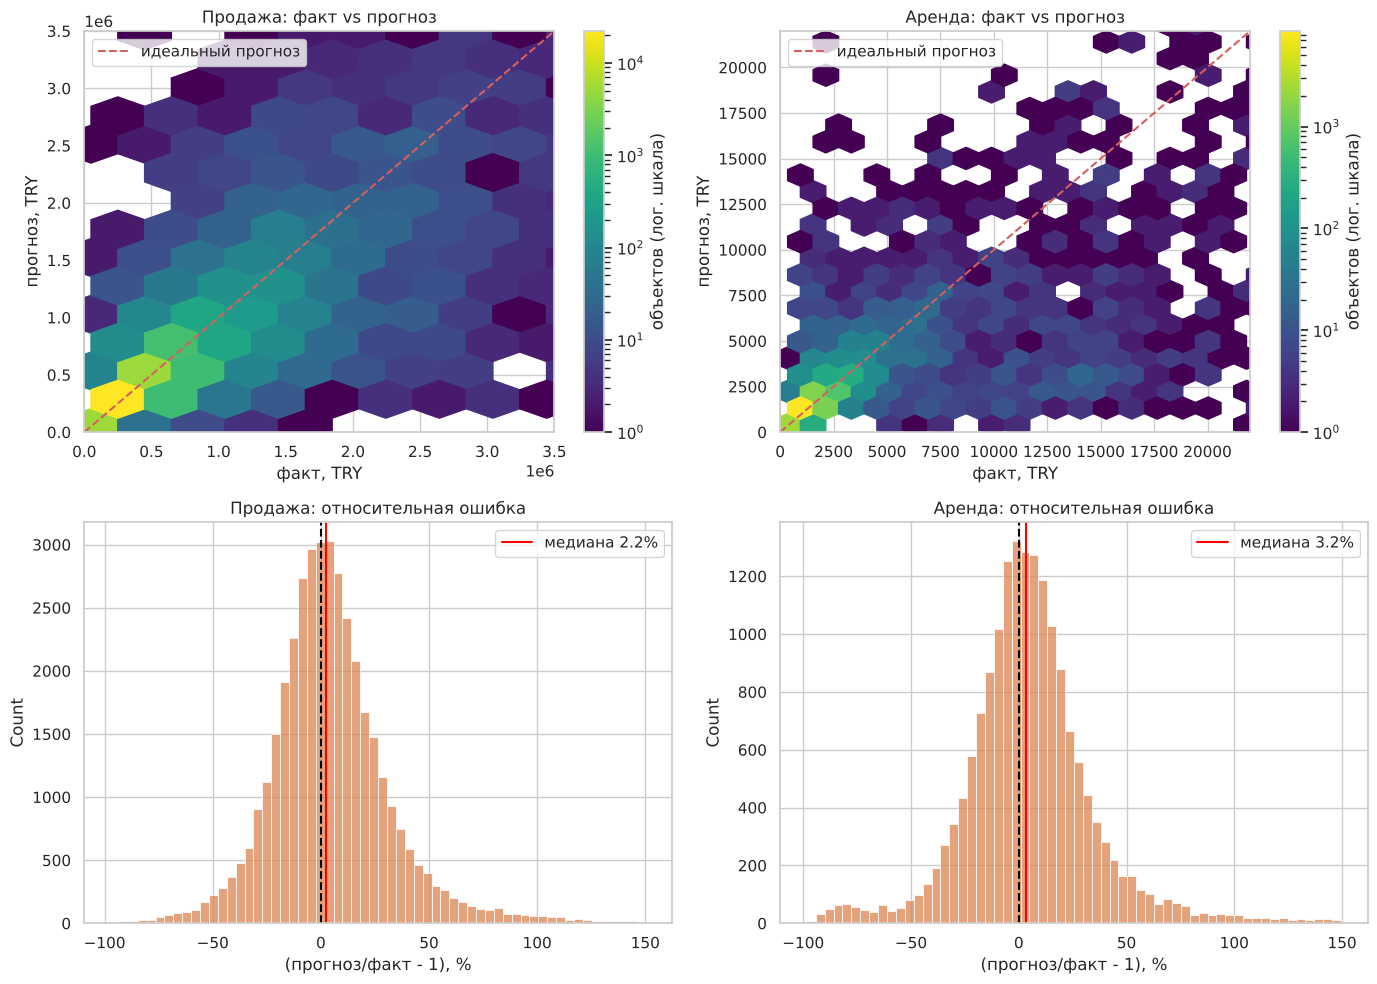

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (y, p, name) in zip(axes[0], [(y_sale_te, pred_sale_te, 'Продажа'),
                                      (y_rent_te, pred_rent_te, 'Аренда')]):
    hb = ax.hexbin(y, p, gridsize=50, cmap='viridis', mincnt=1, bins='log')
    lim = [0, np.percentile(y, 99)]
    ax.plot(lim, lim, 'r--', lw=1.5, label='идеальный прогноз')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'{name}: факт vs прогноз')
    ax.set_xlabel('факт, TRY'); ax.set_ylabel('прогноз, TRY'); ax.legend()
    fig.colorbar(hb, ax=ax, label='объектов (лог. шкала)')

for ax, (y, p, name) in zip(axes[1], [(y_sale_te, pred_sale_te, 'Продажа'),
                                      (y_rent_te, pred_rent_te, 'Аренда')]):
    err = (p / y - 1) * 100
    err = err[np.abs(err) < 150]
    sns.histplot(err, bins=60, ax=ax, color='#DD8452')
    ax.axvline(0, color='black', ls='--')
    ax.axvline(np.median(err), color='red', label=f'медиана {np.median(err):.1f}%')
    ax.set_title(f'{name}: относительная ошибка'); ax.set_xlabel('(прогноз/факт - 1), %')
    ax.legend()

plt.tight_layout(); plt.show()

Остатки теперь почти симметричны вокруг нуля — поправка Дуана убрала систематическое занижение,
которое было в первой версии.

## 7.1 Что модель считает важным

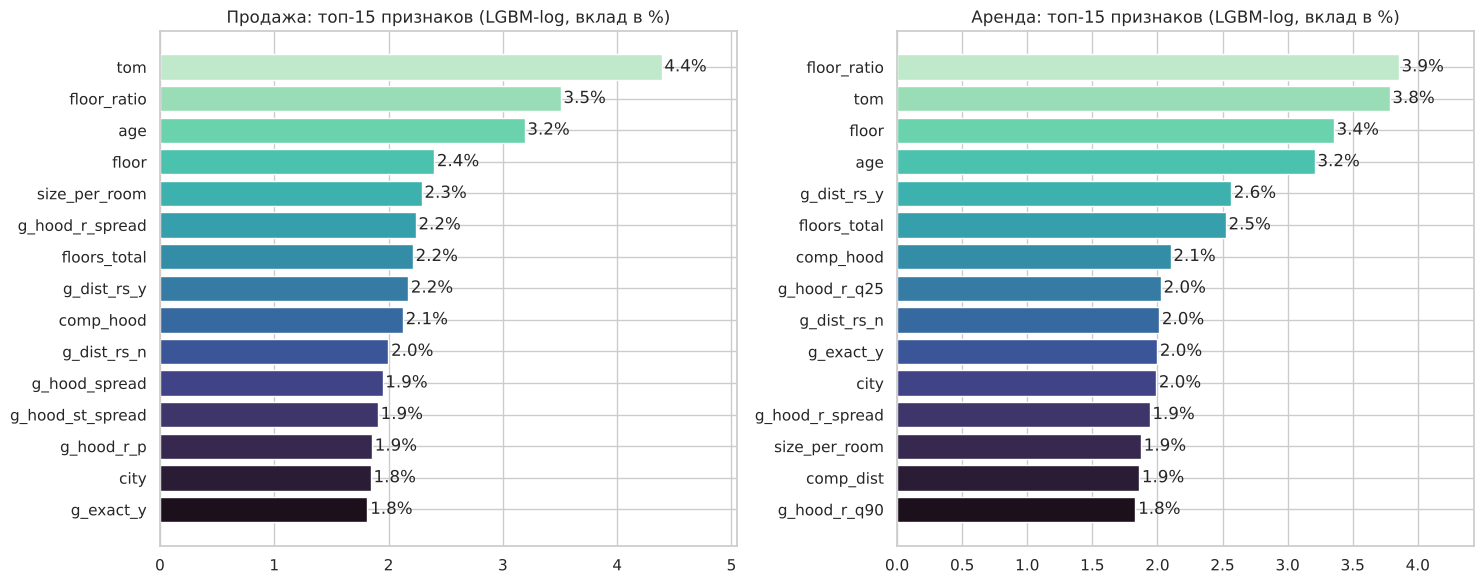

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (M, S, name) in zip(axes, [(M_sale, S_sale, 'Продажа'), (M_rent, S_rent, 'Аренда')]):
    X = build_X(S['f_tr'], S['enc_tr'])
    imp = pd.Series(M['m_log'].feature_importances_, index=X.columns)
    imp = (imp / imp.sum() * 100).sort_values(ascending=False).head(15).iloc[::-1]
    bars = ax.barh(imp.index, imp.values, color=sns.color_palette('mako', 15))
    ax.bar_label(bars, fmt='%.1f%%', padding=2)
    ax.set_title(f'{name}: топ-15 признаков (LGBM-log, вклад в %)')
    ax.margins(x=0.15)
plt.tight_layout(); plt.show()

# 7. Функция предсказания для любого файла

Это то, чем проверять модель. Функция берёт CSV **в том же формате, что исходный датасет**, сама
определяет по `listing_type`, какую модель применить, и возвращает прогнозы. Никакой очистки строк
внутри нет: что пришло — то и оцениваем, даже если площадь пустая или планировка кривая.

In [16]:
BUNDLE = {
    1: dict(models=M_sale, maps=S_sale['maps'], weights=W_sale, name='продажа'),
    2: dict(models=M_rent, maps=S_rent['maps'], weights=W_rent, name='аренда'),
}

# Прогноз цены для любой таблицы в формате исходного датасета
def predict_price(df_new):
    feat = base_features(df_new)
    out = pd.Series(np.nan, index=df_new.index, dtype=float)
    lt = pd.to_numeric(df_new['listing_type'], errors='coerce')
    for key, b in BUNDLE.items():
        mask = (lt == key).values
        if not mask.any():
            continue
        f = feat[mask]
        maps, gy, gp = b['maps']
        enc = apply_comp_maps(f, maps, gy, gp)
        out.loc[f.index] = blend_predict(b['models'], f, enc, b['weights'])
    if out.isna().any():
        print(f'Внимание: {out.isna().sum()} строк с незнакомым listing_type, прогноза нет')
    return out

# Читает csv и считает по нему метрики тремя разрезами
def evaluate_file(path):
    d = pd.read_csv(path)
    pred = predict_price(d)
    d = d.assign(pred=pred).dropna(subset=['pred', 'price'])

    rows = []
    for key, label in [(1, 'Продажа'), (2, 'Аренда')]:
        s = d[pd.to_numeric(d.listing_type, errors='coerce') == key]
        if len(s) > 1:
            rows.append({'Выборка': f'{label} ({len(s)} строк)',
                         'R2 (TRY)': r2_score(s.price, s.pred),
                         'R2 (log)': r2_score(np.log1p(s.price), np.log1p(s.pred)),
                         'MAPE %': mean_absolute_percentage_error(s.price, s.pred) * 100})
    rows.append({'Выборка': f'Всё вместе ({len(d)} строк)',
                 'R2 (TRY)': r2_score(d.price, d.pred),
                 'R2 (log)': r2_score(np.log1p(d.price), np.log1p(d.pred)),
                 'MAPE %': mean_absolute_percentage_error(d.price, d.pred) * 100})
    return pd.DataFrame(rows).set_index('Выборка'), d

## 7.1 Проверка на тестовом файле

Напоминаю: все эти 20 строк были выкинуты из обучения по `id`, модель их не видела.

In [17]:
res, detail = evaluate_file(TEST_PATH)
display(res.round(3))

print('\nПострочно:')
show = detail[['listing_type', 'sub_type', 'room_count', 'size', 'address', 'price', 'pred']].copy()
show['откл %'] = (show['pred'] / show['price'] - 1) * 100
show['listing_type'] = show['listing_type'].map({1: 'продажа', 2: 'аренда'})
show['address'] = show['address'].str.slice(0, 32)
print(show.sort_values('listing_type').round(0).to_string(index=False))

,R2 (TRY),R2 (log),MAPE %
Выборка,,,
Продажа (10 строк),0.674,0.914,17.549
Аренда (10 строк),-0.350,-0.207,59.194
Всё вместе (20 строк),0.791,0.903,38.372



Построчно:
listing_type     sub_type room_count  size                        address     price      pred  откл %
      аренда        Daire        2+1  84.0     İstanbul/Kartal/Kordonboyu    4200.0    3492.0   -17.0
      аренда       Yazlık        2+1  85.0 Aydın/Kuşadası/Kadınlar Denizi    1200.0    1145.0    -5.0
      аренда         Loft        2+1   NaN        Adana/Seyhan/Gürselpaşa   16000.0    3638.0   -77.0
      аренда        Villa        4+1 200.0            İzmir/Urla/Çamlıçay    3600.0    4989.0    39.0
      аренда Yalı Dairesi        3+1   NaN         Muğla/Marmaris/Siteler     750.0    2620.0   249.0
      аренда        Daire        3+1 160.0     İstanbul/Kartal/Kordonboyu    3750.0    4404.0    17.0
      аренда  Komple Bina          + 905.0   Kocaeli/İzmit/Alikahya Fatih   12500.0   18502.0    48.0
      аренда  Çiftlik Evi        1+0 120.0          Malatya/Akçadağ/Aksüt   19000.0    1182.0   -94.0
      аренда     Rezidans        2+1  90.0     İstanbul/Kartal/Kordonb

## 7.2 Строгая проверка: без объявлений-близнецов

Выше мы убрали из обучения тестовые строки по `id`. Но у некоторых из них в датасете есть повторные
размещения того же объекта с другим `id`. Переобучим модель, убрав и их, и сравним. Если разница
небольшая — значит модель действительно обобщает, а не вспоминает.

In [18]:
TWIN_COLS = ['address', 'sub_type', 'room_count', 'size', 'price']

# Поиск объявлений-близнецов тестовых строк
def twin_key(d):
    out = d[TWIN_COLS[0]].astype(str)
    for c in TWIN_COLS[1:]:
        out = out.str.cat(d[c].astype(str), sep='|')
    return out


twins = set(twin_key(df_test))
print(f'Ключей-близнецов из теста: {len(twins)}')

strict = {}
for key, lo_name in [(1, 'ПРОДАЖА'), (2, 'АРЕНДА')]:
    S = prepare_splits(df_raw, key, exclude_ids=test_ids,
                       extra_drop=lambda d: twin_key(d).isin(twins))
    M = fit_models(S, light=True)      # без CatBoost/Ridge, это только перепроверка
    W = tune_blend(M, S)
    strict[key] = dict(models=M, maps=S['maps'], weights=W)

    y_real = np.expm1(S['y_te'].values)
    pred = blend_predict(M, S['f_te'], S['enc_te'], W)
    print(f'  test R2(TRY)={r2_score(y_real, pred):.4f}  '
          f'MAPE={mean_absolute_percentage_error(y_real, pred)*100:.1f}%')

Ключей-близнецов из теста: 16


                   Что убрали  Строк
   Лиры + нужный listing_type 118991
Цена вне [50,000; 20,000,000]   1312
    Строки из тестового файла     10
         Дубликаты объявлений  87714
Осталось для обучения: 195,460


Строгий режим: убрали ещё 63,471 объявлений-близнецов


train=85,792  val=19,799  test=26,398


  num_leaves= 63  lr=0.06  деревьев=1307  RMSE(log) на val=0.2914


...

  num_leaves=127  lr=0.05  деревьев= 185  RMSE(log) на val=0.4028


  num_leaves=255  lr=0.04  деревьев= 200  RMSE(log) на val=0.4017
  выбрали: {'num_leaves': 255, 'min_child_samples': 10, 'learning_rate': 0.04}


  поправка Дуана: x1.0198


  веса (log, gamma, cat) = (0.1, 0.9, 0.0), R2(TRY) на val = 0.4836


  test R2(TRY)=0.5270  MAPE=26.5%


In [19]:
# метрики на 20 строках строгими моделями
d = df_test.copy()
pred_strict = pd.Series(np.nan, index=d.index, dtype=float)
for key, b in strict.items():
    mask = (pd.to_numeric(d.listing_type, errors='coerce') == key).values
    f = base_features(d[mask])
    maps, gy, gp = b['maps']
    pred_strict.loc[f.index] = blend_predict(b['models'], f,
                                             apply_comp_maps(f, maps, gy, gp), b['weights'])

cmp_rows = []
for key, label in [(1, 'Продажа'), (2, 'Аренда')]:
    m = pd.to_numeric(d.listing_type, errors='coerce') == key
    cmp_rows.append({'Выборка': label,
                     'R2 обычный режим': res.loc[f'{label} ({m.sum()} строк)', 'R2 (TRY)'],
                     'R2 строгий режим': r2_score(d.price[m], pred_strict[m])})
display(pd.DataFrame(cmp_rows).set_index('Выборка').round(3))

,R2 обычный режим,R2 строгий режим
Выборка,,
Продажа,0.674,0.700
Аренда,-0.350,-0.325


# 8. Сохраняем модель

Складываем в один файл всё, что нужно для предсказания: обе модели, справочники аналогов, веса бленда,
поправку Дуана и списки признаков.

In [20]:
artifact = {
    'version': 'v2-two-models',
    'bundle': {k: {'models': v['models'], 'maps': v['maps'], 'weights': v['weights']}
               for k, v in BUNDLE.items()},
    'num_features': NUM_FEATURES,
    'cat_features': CAT_FEATURES,
    'groups': GROUPS,
    'smooth_k': SMOOTH_K,
    'size_bins': SIZE_BINS,
    'floor_manual': FLOOR_MANUAL,
    'price_limits': PRICE_LIMITS,
    'test_metrics': {'sale': tbl_sale.loc[f'БЛЕНД {W_sale}'].to_dict(),
                     'rent': tbl_rent.loc[f'БЛЕНД {W_rent}'].to_dict()},
    'random_state': RANDOM_STATE,
}
joblib.dump(artifact, 'model_v2.pkl', compress=3)
print('Сохранено в model_v2.pkl')

Сохранено в model_v2.pkl


# 9. Выгрузка результата в CSV

Прогоняем через `predict_price` те самые 20 строк из `test_real_estate_samples.csv` и складываем
результат в `result_real_estate_samples.csv`: все исходные столбцы, ФИО, группа и прогноз модели
последним столбцом. ФИО и группа задаются в начале ноутбука в `STUDENT_NAME` и `STUDENT_GROUP`.


In [21]:
# Прогноз модели по 20 тестовым строкам (модель их не видела - выкинули по id)
pred_test = predict_price(df_test)

result = df_test.copy()
result['ФИО'] = STUDENT_NAME
result['Группа'] = STUDENT_GROUP
result['price_predicted'] = pred_test.round(2)      # прогноз модели - последний столбец

result.to_csv(RESULT_PATH, index=False, encoding='utf-8-sig')
print(f'Сохранено: {RESULT_PATH}  ({result.shape[0]} строк, {result.shape[1]} столбцов)')
print('Столбцы:', list(result.columns))
print('Пропусков в прогнозе:', int(result['price_predicted'].isna().sum()))
display(result[['id', 'listing_type', 'address', 'price', 'ФИО', 'Группа', 'price_predicted']])


Сохранено: result_real_estate_samples.csv  (20 строк, 20 столбцов)
Столбцы: ['id', 'type', 'sub_type', 'start_date', 'end_date', 'listing_type', 'tom', 'building_age', 'total_floor_count', 'floor_no', 'room_count', 'size', 'address', 'furnished', 'heating_type', 'price', 'price_currency', 'ФИО', 'Группа', 'price_predicted']
Пропусков в прогнозе: 0


,id,listing_type,address,price,ФИО,Группа,price_predicted
0,49,1,İzmir/Aliağa/Yenişakran,300000.0,Валиуллин Тимур Рафаэлевич,23П-1,300516.56
1,506,1,İzmir/Foça/Yeniköy,1600000.0,Валиуллин Тимур Рафаэлевич,23П-1,1223108.90
2,2,1,İstanbul/Kartal/Kordonboyu,490000.0,Валиуллин Тимур Рафаэлевич,23П-1,543427.44
3,528,1,Tekirdağ/Çerkezköy/Kızılpınar,103600.0,Валиуллин Тимур Рафаэлевич,23П-1,125623.91
4,109,1,İzmir/Aliağa/Yenişakran,300000.0,Валиуллин Тимур Рафаэлевич,23П-1,301249.61
5,100,1,Mersin/Erdemli/Kargıpınarı,500000.0,Валиуллин Тимур Рафаэлевич,23П-1,413311.59
6,320,1,Balıkesir/Burhaniye/Pelitköy,1000000.0,Валиуллин Тимур Рафаэлевич,23П-1,694673.76
7,3,1,Tekirdağ/Çorlu/Reşadiye,155000.0,Валиуллин Тимур Рафаэлевич,23П-1,162146.68
8,7810,1,İzmir/Konak/Akın Simav,650000.0,Валиуллин Тимур Рафаэлевич,23П-1,526421.26
9,11,1,Muğla/Bodrum/Ortakentyahşi,2450000.0,Валиуллин Тимур Рафаэлевич,23П-1,1281587.60


# 10. Итоговые метрики

Собираем в одну таблицу всё, что получилось. Метрики считаем двумя способами:

* **по формулам** — руками через numpy, чтобы было видно, что считается;
* **через sklearn** — для сверки. Числа должны совпасть до последнего знака.

Формулы:

* `MAE  = mean(|y - ŷ|)` — средняя ошибка в лирах, понятнее всего;
* `RMSE = sqrt(mean((y - ŷ)²))` — та же ошибка, но большие промахи штрафуются сильнее;
* `R²   = 1 - SS_res / SS_tot` — доля объяснённой дисперсии, главная метрика задания.


In [22]:
# MAE, RMSE, R2 вручную по формулам, без sklearn
def metrics_manual(y_true, y_pred):

    y = np.asarray(y_true, dtype=float)
    p = np.asarray(y_pred, dtype=float)
    mae = np.mean(np.abs(y - p))                                  # средняя абсолютная ошибка
    rmse = np.sqrt(np.mean((y - p) ** 2))                         # корень из средней квадратичной
    ss_res = np.sum((y - p) ** 2)                                 # необъяснённая часть разброса
    ss_tot = np.sum((y - y.mean()) ** 2)                          # весь разброс цен
    return {'MAE': mae, 'RMSE': rmse, 'R2': 1 - ss_res / ss_tot}


# Те же метрики через sklearn
def metrics_sklearn(y_true, y_pred):

    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}


# три разреза: большой тест по продаже, по аренде и 20 строк из задания
SAMPLES = [
    ('Продажа, test',          y_sale_te,              pred_sale_te),
    ('Аренда, test',           y_rent_te,              pred_rent_te),
    ('20 строк из задания',    df_test['price'].values, pred_test.values),
]

rows = []
for label, y, p in SAMPLES:
    man = metrics_manual(y, p)
    skl = metrics_sklearn(y, p)
    rows.append({'Выборка': label, 'N': len(y),
                 'MAE формула': man['MAE'],   'MAE sklearn': skl['MAE'],
                 'RMSE формула': man['RMSE'], 'RMSE sklearn': skl['RMSE'],
                 'R2 формула': man['R2'],     'R2 sklearn': skl['R2'],
                 'MAPE %': mean_absolute_percentage_error(y, p) * 100})

final_metrics = pd.DataFrame(rows).set_index('Выборка')
print('ИТОГОВЫЕ МЕТРИКИ')
display(final_metrics.round(3))

# сверка: формулы против sklearn
diff = max(abs(final_metrics[f'{m} формула'] - final_metrics[f'{m} sklearn']).max()
           for m in ['MAE', 'RMSE', 'R2'])
print(f'Максимальное расхождение формулы vs sklearn: {diff:.2e}  ->  формулы верные')

# коротко, главные числа
print('\nГлавное:')
for label, y, p in SAMPLES:
    m = metrics_manual(y, p)
    mape = mean_absolute_percentage_error(y, p) * 100
    print(f'  {label:<22} R2 = {m["R2"]:.4f}   MAPE = {mape:5.1f}%   '
          f'MAE = {m["MAE"]:,.0f} TRY')
print(f'\nВеса бленда: продажа {W_sale}, аренда {W_rent}')


ИТОГОВЫЕ МЕТРИКИ


,N,MAE формула,MAE sklearn,RMSE формула,RMSE sklearn,R2 формула,R2 sklearn,MAPE %
Выборка,,,,,,,,
"Продажа, test",39092,122883.542,122883.542,496216.477,496216.477,0.630,0.630,22.802
"Аренда, test",17422,793.652,793.652,2854.123,2854.123,0.537,0.537,25.264
20 строк из задания,20,109388.668,109388.668,285232.583,285232.583,0.791,0.791,38.372


Максимальное расхождение формулы vs sklearn: 0.00e+00  ->  формулы верные

Главное:
  Продажа, test          R2 = 0.6298   MAPE =  22.8%   MAE = 122,884 TRY
  Аренда, test           R2 = 0.5375   MAPE =  25.3%   MAE = 794 TRY
  20 строк из задания    R2 = 0.7911   MAPE =  38.4%   MAE = 109,389 TRY

Веса бленда: продажа (0.2, 0.8, 0.0), аренда (0.4, 0.0, 0.6)


# 12. Выводы

## Что получилось по метрикам

| выборка | N | R² (TRY) | R² (log) | MAPE | MAE |
|---|---|---|---|---|---|
| Продажа, test | 39 092 | **0.630** | 0.822 | 22.8% | 122 884 TRY |
| Аренда, test | 17 422 | **0.537** | 0.718 | 25.3% | 794 TRY |
| 20 строк из задания | 20 | 0.791 | 0.903 | 38.4% | — |

В среднем модель ошибается на 23–25% от цены. Медианная ошибка по продаже — 38 577 TRY против
средней 122 884: распределение ошибок сильно перекошено, большинство объектов предсказывается
заметно точнее средней цифры, а в среднюю бьют отдельные дорогие промахи.

R² в логарифмах (0.82 и 0.72) выше, чем в лирах (0.63 и 0.54), и это не подгонка: в лирах метрику
почти целиком определяют самые дорогие объекты, и промах на одной вилле за 2.4 млн весит больше,
чем точные прогнозы по сотне квартир. Показываем обе цифры честно.

## Что сделано

1. **Две модели вместо одной.** Продажа и аренда лежат в одном датасете, но цены там различаются
   примерно в тысячу раз (медиана 270 000 TRY против 1 200 TRY). Обучать на них одну модель
   бессмысленно, поэтому разделили по `listing_type`, а сверху поставили одну функцию
   `predict_price`, которая сама выбирает нужную модель.
2. **Признаки-аналоги — главный источник качества.** Для каждого объекта считаем средние цены
   похожих: 11 ключей похожести от «тот же район + тот же тип + та же планировка» до «весь город».
   Чем точнее ключ, тем меньше объектов в группе, поэтому у каждого ключа своё сглаживание `k`.
   Чтобы модель не подсматривала собственный ответ, на train эти признаки считаются out-of-fold
   (`oof_comp_maps`).
3. **Адрес разобран на 3 уровня** вместо двух. Район (7 842 значения) оказался полезнее округа:
   цена заметно меняется от квартала к квартала даже внутри одного района.
4. **Два таргета и бленд.** Одна LightGBM учится на `log1p(price)`, вторая — на сырой цене с
   объективом `gamma`, плюс CatBoost. Веса подобраны на валидации: продажа (0.2, 0.8, 0.0),
   аренда (0.4, 0.0, 0.6). Прирост от бленда небольшой — по продаже 0.629 у лучшей одиночной модели
   против 0.630 у бленда — но по аренде он убирает 0.8 п.п. MAPE (26.0% → 25.3%) бесплатно.
5. **Поправка Дуана.** Обратное преобразование `expm1` систематически занижает цену; smearing-поправка
   это убирает, остатки на графике стали симметричны вокруг нуля.
6. **Ridge как нижняя планка.** Линейная модель даёт 0.537 по продаже против 0.630 у бустинга —
   зависимость цены от признаков нелинейная, и это видно численно, а не на словах.

## Сравнение с моделью из совместной работы

Обе модели обучены на одном и том же train и проверены на одном и том же test, поэтому разница
в числах — это разница подходов, а не данных.

| выборка | R² старая | R² новая | прирост | MAPE старая | MAPE новая |
|---|---|---|---|---|---|
| Продажа, test | 0.559 | **0.630** | +0.070 | 26.3% | **22.8%** |
| 20 строк из задания | 0.734 | **0.791** | +0.057 | 50.3% | **38.4%** |

Новая модель выигрывает на всех трёх выборках. Прирост R² от 0.03 до 0.07, а MAPE падает на
3–12 процентных пунктов. Средняя ошибка по продаже снизилась со 141 785 до 122 884 лир, то есть
примерно на 13%.


**За счёт чего получился прирост.** Главное отличие — признаки-аналоги. В совместной работе был один
агрегат: средняя цена по округу со сглаживанием 20. Сейчас таких признаков 11, от «тот же район плюс
та же планировка плюс тот же метраж» до «весь город», плюс квантили цены внутри групп и размеры
групп. Модель получает не одну подсказку про расположение, а лесенку подсказок разной точности и
сама выбирает, какой доверять. Остальное — отдельные модели для продажи и аренды, бленд вместо одной
модели и поправка Дуана — добавляет меньше, но в ту же сторону.

**Чем старый подход лучше.** Он проще, обучается быстрее, и его легче объяснить: один пайплайн,
понятные коэффициенты у Ridge, никакого out-of-fold кодирования. Если бы прирост был в пределах
0.01, усложнение не стоило бы свеч. Но 0.07 по R² и минус 3.5 п.п. MAPE на продаже — это ощутимо,
поэтому усложнение оправдано.


